<a href="https://colab.research.google.com/github/fauzia-annisa/Multimodal-AI-Bitcoin-Analytics-Dashboard-ML-NLP/blob/main/Copy_of_multimodal_ai_bitcoin_analytics_dashboard_ml_nlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install tools
!pip install yfinance textblob matplotlib seaborn


In [ ]:
# Import libraries
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
import datetime


In [ ]:
# Download Bitcoin history
ticker = yf.Ticker("BTC-USD")
df = ticker.history(period="60d") # Mengambil data 60 hari terakhir
print(f"Berhasil mengunduh {len(df)} baris data Bitcoin.")
df.tail()


Berhasil mengunduh 60 baris data Bitcoin.


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-10-09 00:00:00+00:00,81676.335938,83418.296875,81557.703125,82546.320312,24521046869,0.0,0.0
2026-10-10 00:00:00+00:00,82546.320312,83092.031250,82473.039062,82912.226562,12485050512,0.0,0.0
2026-10-11 00:00:00+00:00,82912.226562,84103.625000,82722.109375,83679.468750,12536449881,0.0,0.0
2026-10-12 00:00:00+00:00,83679.468750,84249.218750,81681.632812,81762.562500,26546289120,0.0,0.0
2026-10-13 00:00:00+00:00,81754.484375,84059.523438,81197.992188,83224.039062,31322337280,0.0,0.0


In [ ]:
# Calculate Moving Averages (ML Features)
df['MA_5'] = df['Close'].rolling(window=5).mean()
df['MA_20'] = df['Close'].rolling(window=20).mean()
print("Fitur Tren Harga (MA5 dan MA20) berhasil dibuat.")


Fitur Tren Harga (MA5 dan MA20) berhasil dibuat.


In [ ]:
# Calculate Momentum Indicator
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df['RSI'] = 100 - (100 / (1 + rs))
print("Fitur Momentum (RSI) berhasil dihitung.")


Fitur Momentum (RSI) berhasil dihitung.


In [ ]:
# Define News Data for NLP
berita_list = [
    "Bitcoin price targets new all-time highs as institutional adoption grows rapidly.",
    "Regulatory concerns in Asia cause sudden drop in cryptocurrency market confidence.",
    "Major tech company announces plans to hold Bitcoin on its corporate balance sheet.",
    "Whales are accumulating Bitcoin quietly despite the short term price stagnation."
]
print(f"Berhasil mengumpulkan {len(berita_list)} berita global terbaru.")


Berhasil mengumpulkan 4 berita global terbaru.


In [ ]:
# Process Sentiment Analysis
skor_sentimen = []
for berita in berita_list:
    analisis = TextBlob(berita)
    skor_sentimen.append(analisis.sentiment.polarity)

df_sentimen = pd.DataFrame({
    'Berita': berita_list,
    'Skor_Sentimen': skor_sentimen
})
rata_sentimen = df_sentimen['Skor_Sentimen'].mean()
print(f"Rata-rata sentimen pasar hari ini: {rata_sentimen:.2f} (Skor > 0 berarti Bullish)")


Rata-rata sentimen pasar hari ini: 0.04 (Skor > 0 berarti Bullish)


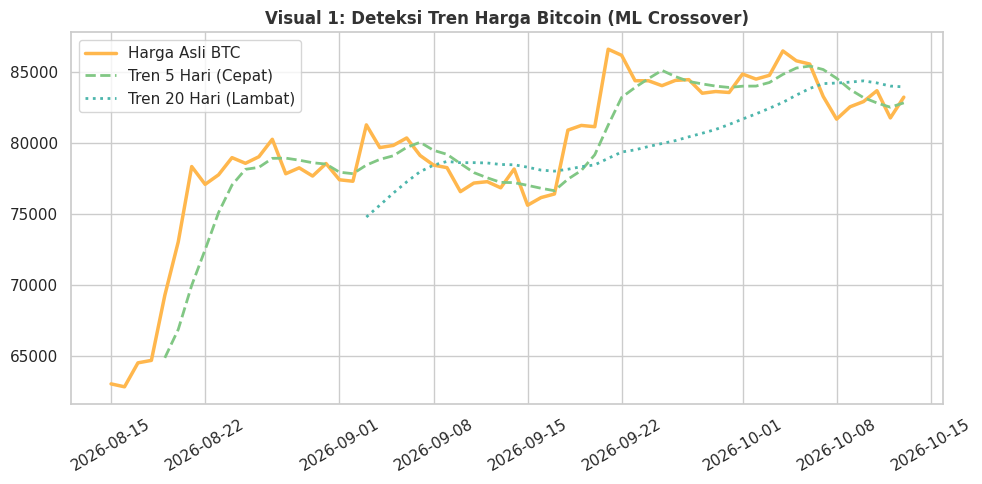

In [ ]:
# Visual 1 - Price vs Moving Averages (Soft Theme)
sns.set_theme(style="whitegrid") # Mengubah background ke putih bersih agar warna soft lebih keluar
plt.figure(figsize=(10, 5))

# Menggunakan warna hijau lembut (#81c784) dan oranye lembut (#ffb74d)
plt.plot(df.index, df['Close'], label='Harga Asli BTC', color='#ffb74d', linewidth=2.5)
plt.plot(df.index, df['MA_5'], label='Tren 5 Hari (Cepat)', color='#81c784', linestyle='--', linewidth=2)
plt.plot(df.index, df['MA_20'], label='Tren 20 Hari (Lambat)', color='#4db6ac', linestyle=':', linewidth=2)

plt.title("Visual 1: Deteksi Tren Harga Bitcoin (ML Crossover)", fontsize=12, fontweight='bold', color='#333333')
plt.legend(frameon=True, facecolor='white')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("visual_1_trends.png")
plt.show()


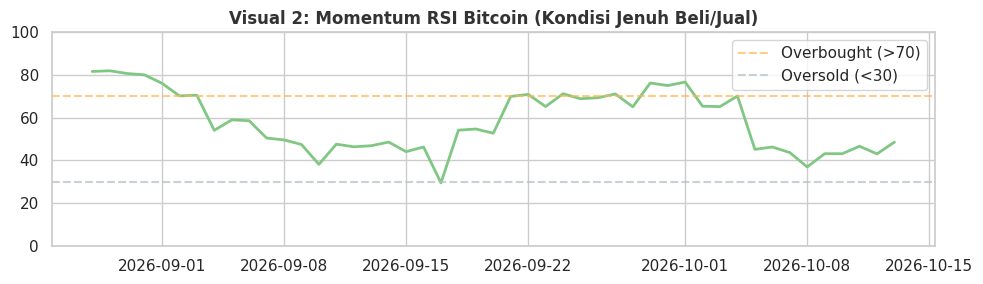

In [ ]:
# Visual 2 - RSI Momentum Chart (Soft Theme)
plt.figure(figsize=(10, 3))

# Plot garis RSI dengan warna hijau lembut
plt.plot(df.index, df['RSI'], color='#81c784', linewidth=2)

# Batas jenuh menggunakan warna oranye lembut transparan
plt.axhline(70, color='#ffb74d', linestyle='--', alpha=0.7, label='Overbought (>70)', linewidth=1.5)
plt.axhline(30, color='#b0bec5', linestyle='--', alpha=0.7, label='Oversold (<30)', linewidth=1.5)

plt.title("Visual 2: Momentum RSI Bitcoin (Kondisi Jenuh Beli/Jual)", fontsize=12, fontweight='bold', color='#333333')
plt.ylim(0, 100)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig("visual_2_rsi.png")
plt.show()


/tmp/ipykernel_463/64114282.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_sentimen.index, y=df_sentimen['Skor_Sentimen'], palette=colors_palette)


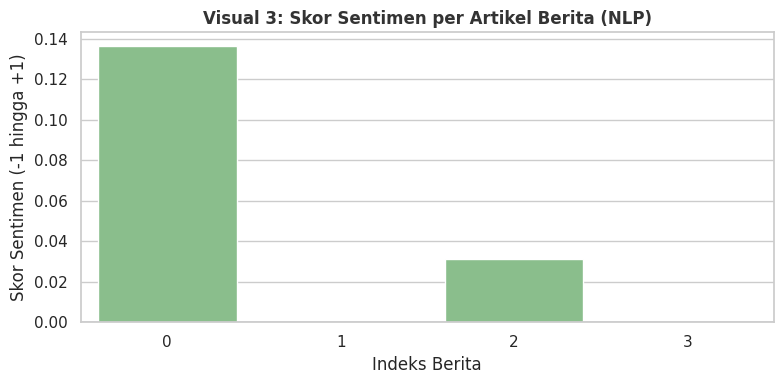

In [ ]:
# SEL 11: Sentiment Breakdown (Soft Theme)
plt.figure(figsize=(8, 4))

# Memisahkan warna bar: hijau lembut untuk positif, oranye lembut untuk negatif
colors_palette = ['#81c784' if x > 0 else '#ffb74d' for x in df_sentimen['Skor_Sentimen']]

sns.barplot(x=df_sentimen.index, y=df_sentimen['Skor_Sentimen'], palette=colors_palette)
plt.axhline(0, color='#78909c', linewidth=1, linestyle='-')

plt.title("Visual 3: Skor Sentimen per Artikel Berita (NLP)", fontsize=12, fontweight='bold', color='#333333')
plt.ylabel("Skor Sentimen (-1 hingga +1)")
plt.xlabel("Indeks Berita")
plt.tight_layout()
plt.savefig("visual_3_sentiment.png")
plt.show()


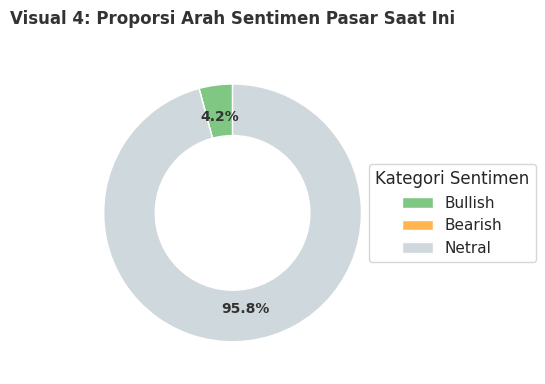

In [ ]:
# Visual 4 - Combined Dashboard Summary (Fixed Anti-Overlap)
plt.figure(figsize=(6, 4))

# Data sentimen
nilai_sentimen = [max(0, rata_sentimen), max(0, -rata_sentimen), 1-abs(rata_sentimen)]
labels_nama = ['Bullish', 'Bearish', 'Netral']
warna_palette = ['#81c784', '#ffb74d', '#cfd8dc']

# Fungsi kustom untuk menyembunyikan angka 0.0% agar tidak menumpuk
def format_persen(pct):
    return f'{pct:.1f}%' if pct > 0 else ''

# Membuat chart TANPA label langsung di lingkaran (labels=None) untuk mencegah tabrakan teks
wedges, texts, autotexts = plt.pie(
    nilai_sentimen,
    labels=None,
    colors=warna_palette,
    autopct=format_persen,
    startangle=90,
    pctdistance=0.75,
    textprops={'fontsize': 10, 'weight': 'bold', 'color': '#333333'}
)

# Membuat lingkaran di tengah agar menjadi donut chart yang modern
centre_circle = plt.Circle((0,0), 0.60, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

# Menambahkan LEGEND (Kotak Keterangan) di samping agar teks tidak menabrak lingkaran grafik
plt.legend(
    wedges,
    labels_nama,
    title="Kategori Sentimen",
    loc="center left",
    bbox_to_anchor=(0.9, 0, 0.5, 1),
    frameon=True,
    facecolor='white'
)

plt.title("Visual 4: Proporsi Arah Sentimen Pasar Saat Ini", fontsize=12, fontweight='bold', color='#333333', pad=20)
plt.tight_layout()
plt.savefig("visual_4_summary.png", bbox_inches='tight')
plt.show()


In [ ]:
# Final Multimodal AI Recommendation
harga_skrg = df['Close'].iloc[-1]
ma5_skrg = df['MA_5'].iloc[-1]
rsi_skrg = df['RSI'].iloc[-1]

print("====== LAPORAN KEPUTUSAN MULTIMODAL AI ======")
print(f"• Analisis Tren (ML) : {'UPTREND' if harga_skrg > ma5_skrg else 'DOWNTREND'}")
print(f"• Momentum (RSI)     : {rsi_skrg:.1f} ({'Jenuh Beli' if rsi_skrg > 70 else 'Jenuh Jual' if rsi_skrg < 30 else 'Normal'})")
print(f"• Analisis Teks (NLP): {'POSITIF / BULLISH' if rata_sentimen > 0 else 'NEGATIF / BEARISH'}")
print("=============================================")

# Logika Penggabungan Sinyal
if harga_skrg > ma5_skrg and rata_sentimen > 0:
    print("🚀 REKOMENDASI AKHIR AI: STRONG BUY")
elif harga_skrg < ma5_skrg and rata_sentimen < 0:
    print("🚨 REKOMENDASI AKHIR AI: STRONG SELL")
else:
    print("⏳ REKOMENDASI AKHIR AI: HOLD / KONDISI PASAR FLUKTUATIF")


====== LAPORAN KEPUTUSAN MULTIMODAL AI ======
• Analisis Tren (ML) : UPTREND
• Momentum (RSI)     : 48.6 (Normal)
• Analisis Teks (NLP): POSITIF / BULLISH
🚀 REKOMENDASI AKHIR AI: STRONG BUY
